# LSTMD workload forecasting: 11-trace anomaly-aware experiment


It evaluates the four original LSTMD configurations on the current 11-trace workload set. The paper's Table 1 values are retained as contextual reference values, not as an exact like-for-like reproduction because this run excludes ali18. The model is **LSTMD** (Conv1D -> LSTM -> MLP -> Gaussian output, trained with negative log-likelihood):

| Label | Training | Prediction | Fits |
|---|---|---|---|
| **S-U-LSTMD** | single trace | univariate (CPU or memory) | 11 traces x 2 = 22 |
| **S-B-LSTMD** | single trace | bivariate (CPU + memory) | 12 |
| **S-B-LSTMD** | single trace | bivariate (CPU + memory) | 11 traces = 11 |
| **M-U-LSTMD** | all 11 traces together | univariate | 2 (one per resource) |
| **M-B-LSTMD** | all 11 traces together | bivariate | 1 |

Each fit runs for up to **500 epochs, 1 seed/iteration**, restoring the best validation-loss weights, with the saved hyperparameters of that configuration (`hyperparams/{univariate,bivariate,multiunivariate,multibivariate}`). Table 1 = mean MSE/MAE over the 11 traces' test splits, CPU and memory. Window = 288, horizon = 2. Targets are split chronologically: 80% train/validation, with the final 20% of that segment used for validation (approximately 64/16/20 train/validation/test).

**Anomaly extension:** runs each configuration twice: (1) original raw-workload LSTMD and (2) anomaly-aware LSTMD, which receives causal binary anomaly flags and soft anomaly scores alongside CPU/memory history. The prediction targets remain the original CPU/memory values. The anomaly detector is fitted only on the fitting prefix (approximately the first 64%) of each trace and uses only past-looking rolling features.

**Setup:** Add Input -> your **ML_PROJ_DATASET**, set Accelerator to GPU, Run All. Results and models are written to `/kaggle/working/lstmd_anomaly_output/` after every fit. If the session stops, re-run and it resumes (finished fits are skipped).

**Important:** This notebook preserves LSTMD's Gaussian negative log-likelihood (NLL). It does not replace NLL with the LSTM experiment's MSE or cost-sensitive loss. The anomaly extension changes the input features only. With all four modes and both input variants, the run contains 72 fits (36 raw + 36 anomaly-aware). The four modes are S-U, S-B, M-U and M-B.

In [1]:
# ---------- CONFIG ----------
import os, glob, json, time, zipfile
from pathlib import Path
from statistics import NormalDist
import numpy as np
import pandas as pd

MODES = ["S-U", "S-B", "M-U", "M-B"]   # any subset, e.g. ["M-B"] for a quick run
EPOCHS = 500
ITERATIONS = 1             # single training run per fit
WIN, HORIZON = 288, 2
TRAIN_SPLIT = 0.8
VAL_SPLIT = 0.2            # final 20% of pre-test target windows is validation
SEED = 0
RESUME = True              # skip fits already recorded in the 11-trace output folder
LOG_EVERY = 25             # print a progress line every N epochs

# False = run all 500 epochs (best-val-loss weights are restored at the end).
# True  = stop early if val_loss doesn't improve for PATIENCE epochs.
EARLY_STOPPING = False
PATIENCE = 50

MODEL_NAME = "LSTMD"
INPUT_VARIANTS = ["raw", "anomaly"]  # run both for a paired architecture comparison
TRACES = ["gc11", "gc19_a", "gc19_b", "gc19_c", "gc19_d", "gc19_e", "gc19_f", "gc19_g", "gc19_h",
          "ali20_c", "ali20_g"]  # ali18 excluded to match the current 11-trace experiment
RESOURCES = ["avgcpu", "avgmem"]      # channel 0 = CPU ("processing units"), channel 1 = memory
SERVICE_LEVELS = [0.90, 0.91, 0.92, 0.93, 0.94, 0.95, 0.96, 0.97, 0.98, 0.99, 0.995]
SPIKE_Q = 0.95  # spike-event threshold from training-prefix positive rises

# Paper Table 1, LSTMD rows: (CPU MSE, CPU MAE, Memory MSE, Memory MAE)
PAPER = {"S-U-LSTMD": (0.0040, 0.0455, 0.0041, 0.0420), "S-B-LSTMD": (0.0061, 0.0556, 0.0088, 0.0631),
         "M-U-LSTMD": (0.0041, 0.0464, 0.0044, 0.0439), "M-B-LSTMD": (0.0046, 0.0446, 0.0046, 0.0446)}

# Saved hyperparameters of every configuration (from the repo's hyperparams/ CSVs).
# Keys: "S-U|<trace>|<cpu|mem>", "S-B|<trace>", "M-U|<cpu|mem>", "M-B"
HP = json.loads('''{"S-U|gc11|cpu":{"first_conv_dim":64,"first_conv_kernel":11,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":16,"first_dense_dim":64,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-U|gc11|mem":{"first_conv_dim":32,"first_conv_kernel":3,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":16,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-B|gc11":{"first_conv_dim":32,"first_conv_kernel":11,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":32,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"rmsprop","lr":0.001,"momentum":0.9,"decay":0.0001},"S-U|gc19_a|cpu":{"first_conv_dim":64,"first_conv_kernel":11,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":32,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-U|gc19_a|mem":{"first_conv_dim":32,"first_conv_kernel":3,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":64,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-B|gc19_a":{"first_conv_dim":32,"first_conv_kernel":3,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":16,"first_dense_activation":"relu","mlp_units":[32],"batch_size":512,"optimizer":"rmsprop","lr":0.001,"momentum":0.9,"decay":0.0001},"S-U|gc19_b|cpu":{"first_conv_dim":128,"first_conv_kernel":3,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":32,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"rmsprop","lr":0.001,"momentum":0.9,"decay":0.0001},"S-U|gc19_b|mem":{"first_conv_dim":32,"first_conv_kernel":3,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":64,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-B|gc19_b":{"first_conv_dim":32,"first_conv_kernel":3,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":16,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"rmsprop","lr":0.001,"momentum":0.9,"decay":0.001},"S-U|gc19_c|cpu":{"first_conv_dim":64,"first_conv_kernel":5,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":32,"first_dense_activation":"relu","mlp_units":[32],"batch_size":512,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-U|gc19_c|mem":{"first_conv_dim":128,"first_conv_kernel":5,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":16,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-B|gc19_c":{"first_conv_dim":64,"first_conv_kernel":5,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":32,"first_dense_dim":64,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"rmsprop","lr":0.001,"momentum":0.9,"decay":0.001},"S-U|gc19_d|cpu":{"first_conv_dim":32,"first_conv_kernel":11,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":32,"first_dense_dim":16,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-U|gc19_d|mem":{"first_conv_dim":64,"first_conv_kernel":3,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":64,"first_dense_activation":"relu","mlp_units":[32],"batch_size":512,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-B|gc19_d":{"first_conv_dim":64,"first_conv_kernel":5,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":64,"first_dense_activation":"relu","mlp_units":[32],"batch_size":512,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-U|gc19_e|cpu":{"first_conv_dim":128,"first_conv_kernel":7,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":16,"first_dense_activation":"relu","mlp_units":[32],"batch_size":512,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-U|gc19_e|mem":{"first_conv_dim":32,"first_conv_kernel":3,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":64,"first_dense_activation":"relu","mlp_units":[32],"batch_size":1024,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-B|gc19_e":{"first_conv_dim":64,"first_conv_kernel":3,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":64,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-U|gc19_f|cpu":{"first_conv_dim":128,"first_conv_kernel":3,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":64,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"rmsprop","lr":0.001,"momentum":0.9,"decay":0.001},"S-U|gc19_f|mem":{"first_conv_dim":32,"first_conv_kernel":11,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":16,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"rmsprop","lr":0.001,"momentum":0.9,"decay":0.0001},"S-B|gc19_f":{"first_conv_dim":128,"first_conv_kernel":3,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":16,"first_dense_dim":32,"first_dense_activation":"relu","mlp_units":[32],"batch_size":1024,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-U|gc19_g|cpu":{"first_conv_dim":32,"first_conv_kernel":5,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":16,"first_dense_activation":"relu","mlp_units":[32],"batch_size":512,"optimizer":"adam","lr":0.0001,"momentum":0.9,"decay":0.0001},"S-U|gc19_g|mem":{"first_conv_dim":32,"first_conv_kernel":7,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":64,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-B|gc19_g":{"first_conv_dim":64,"first_conv_kernel":11,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":16,"first_dense_dim":16,"first_dense_activation":"relu","mlp_units":[32],"batch_size":512,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-U|gc19_h|cpu":{"first_conv_dim":32,"first_conv_kernel":7,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":32,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"rmsprop","lr":0.001,"momentum":0.9,"decay":0.001},"S-U|gc19_h|mem":{"first_conv_dim":128,"first_conv_kernel":11,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":64,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.001},"S-B|gc19_h":{"first_conv_dim":128,"first_conv_kernel":5,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":16,"first_dense_activation":"relu","mlp_units":[32],"batch_size":512,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-U|ali18|cpu":{"first_conv_dim":64,"first_conv_kernel":11,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":32,"first_dense_activation":"relu","mlp_units":[32],"batch_size":512,"optimizer":"rmsprop","lr":0.0001,"momentum":0.9,"decay":0.001},"S-U|ali18|mem":{"first_conv_dim":64,"first_conv_kernel":11,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":64,"first_dense_activation":"relu","mlp_units":[32],"batch_size":512,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-B|ali18":{"first_conv_dim":32,"first_conv_kernel":11,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":32,"first_dense_activation":"relu","mlp_units":[32],"batch_size":512,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-U|ali20_c|cpu":{"first_conv_dim":128,"first_conv_kernel":7,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":32,"first_dense_activation":"relu","mlp_units":[32],"batch_size":256,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-U|ali20_c|mem":{"first_conv_dim":128,"first_conv_kernel":3,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":16,"first_dense_dim":32,"first_dense_activation":"relu","mlp_units":[32],"batch_size":512,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-B|ali20_c":{"first_conv_dim":32,"first_conv_kernel":5,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":16,"first_dense_dim":64,"first_dense_activation":"relu","mlp_units":[32],"batch_size":1024,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.001},"S-U|ali20_g|cpu":{"first_conv_dim":64,"first_conv_kernel":7,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":16,"first_dense_activation":"relu","mlp_units":[32],"batch_size":1024,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-U|ali20_g|mem":{"first_conv_dim":64,"first_conv_kernel":3,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":64,"first_dense_dim":64,"first_dense_activation":"relu","mlp_units":[32],"batch_size":512,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"S-B|ali20_g":{"first_conv_dim":64,"first_conv_kernel":3,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":32,"first_dense_dim":32,"first_dense_activation":"relu","mlp_units":[32],"batch_size":512,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001},"M-U|cpu":{"first_conv_dim":32,"first_conv_kernel":3,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":8,"first_dense_dim":8,"first_dense_activation":"relu","mlp_units":[32,32],"batch_size":256,"optimizer":"rmsprop","lr":0.001,"momentum":0.9,"decay":0.001},"M-U|mem":{"first_conv_dim":16,"first_conv_kernel":5,"first_conv_activation":"relu","cnn_layers":3,"second_lstm_dim":32,"first_dense_dim":8,"first_dense_activation":"relu","mlp_units":[32,16],"batch_size":1024,"optimizer":"rmsprop","lr":0.001,"momentum":0.9,"decay":0.0001},"M-B":{"first_conv_dim":16,"first_conv_kernel":3,"first_conv_activation":"relu","cnn_layers":1,"second_lstm_dim":32,"first_dense_dim":8,"first_dense_activation":"relu","mlp_units":[32,32],"batch_size":128,"optimizer":"adam","lr":0.001,"momentum":0.9,"decay":0.0001}}''')

OUT = Path("/kaggle/working/lstmd_11trace_anomaly_output_v2") if Path("/kaggle/working").exists() else Path("lstmd_11trace_anomaly_output_v2")
for sub in ("models", "history", "ckpt", "predictions"):
    (OUT / sub).mkdir(parents=True, exist_ok=True)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPUs:", gpus if gpus else "NONE (500-epoch fits on CPU will be extremely slow; set Accelerator to GPU)")

TensorFlow 2.21.0 | Keras 3.13.2
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 1. Load the 11 traces from ML_PROJ_DATASET

Looks under `/kaggle/input` for the 11 CSVs (`time, avgcpu, avgmem`), so it works whatever the exact mount path is. The data is already normalized, so no extra scaler is applied.

In [2]:
DATASET_SLUG = "ml-proj-dataset"
def norm(x): return x.lower().replace("_", "-")

all_csvs = glob.glob("/kaggle/input/**/*.csv", recursive=True)
preferred = [p for p in all_csvs if DATASET_SLUG in norm(p)]
found = {}
for p in preferred + all_csvs:
    stem = Path(p).stem
    if stem in TRACES and stem not in found:
        found[stem] = p
missing = [t for t in TRACES if t not in found]
if missing:
    raise FileNotFoundError(f"Missing traces {missing}. Attach ML_PROJ_DATASET via Add Input. "
                            f"CSVs visible under /kaggle/input: {sorted(all_csvs)[:30]}")

series = {}
for t in TRACES:
    df = pd.read_csv(found[t])
    assert {"avgcpu", "avgmem"} <= set(df.columns), f"{t}: expected avgcpu/avgmem, got {list(df.columns)}"
    series[t] = df[RESOURCES].to_numpy(dtype=np.float32)
    print(f"{t:8s} {len(df):6d} rows  <- {found[t]}")

# ---- Causal anomaly features (same detector used in the main anomaly pipeline) ----
from sklearn.ensemble import IsolationForest

ANOMALY_TRAIN_FRAC = 0.70
ANOMALY_WINDOW = 36
ANOMALY_SEED = 42
ANOMALY_Q = 0.95
ANOMALY_MIN_VOTES = 2

def rolling_mad(s, w):
    return s.rolling(w).apply(lambda v: np.median(np.abs(v - np.median(v))), raw=True)

def anomaly_components(x, n_train):
    floor = 0.25 * x.iloc[:n_train].std() + 1e-6
    delta = x.diff()
    med = x.rolling(ANOMALY_WINDOW).median().shift(1)
    scale = (1.4826 * rolling_mad(x, ANOMALY_WINDOW)).shift(1).clip(lower=floor)
    rz = (x - med) / scale
    dscale = (1.4826 * rolling_mad(delta, ANOMALY_WINDOW)).shift(1).clip(lower=floor * 0.5)
    jz = delta / dscale
    ew = x.ewm(span=12, adjust=False).mean().shift(1)
    residual = x - ew
    escale = residual.ewm(span=ANOMALY_WINDOW, adjust=False).std().shift(1).clip(lower=floor * 0.5)
    ez = residual / escale
    vr = (x.rolling(6).std() / (x.rolling(ANOMALY_WINDOW).std() + 1e-6)).shift(1)
    return pd.DataFrame({"rz": rz, "jz": jz, "ez": ez, "vr": vr, "x": x, "d": delta}).fillna(0.0)

def detect_anomalies(values):
    df = pd.Series(values.astype(np.float64))
    n_train = int(len(df) * ANOMALY_TRAIN_FRAC)
    F = anomaly_components(df, n_train)
    iso = IsolationForest(n_estimators=300, contamination="auto",
                          random_state=ANOMALY_SEED, n_jobs=-1)
    iso.fit(F.iloc[ANOMALY_WINDOW:n_train].values)
    if_score = -iso.score_samples(F.values)
    if_threshold = np.quantile(if_score[ANOMALY_WINDOW:n_train], ANOMALY_Q)

    votes = np.vstack([
        (F["rz"] > 3.0).values,
        (F["jz"] > 3.0).values,
        (F["ez"] > 3.0).values,
        (if_score > if_threshold) & (F["rz"].values > 0)
    ]).astype(float)
    flag = ((votes.sum(axis=0) >= ANOMALY_MIN_VOTES) & (F["rz"].values > 0)).astype(np.float32)

    train_max = max(float(if_score[ANOMALY_WINDOW:n_train].max()), float(if_threshold) + 1e-6)
    if_scale = np.clip((if_score - if_threshold) / (train_max - if_threshold + 1e-9) + 0.5, 0, 1)
    soft = np.vstack([
        np.clip(F["rz"].values / 6.0, 0, 1),
        np.clip(F["jz"].values / 6.0, 0, 1),
        np.clip(F["ez"].values / 6.0, 0, 1),
        if_scale * (F["rz"].values > 0)
    ]).mean(axis=0).astype(np.float32)

    flag[:ANOMALY_WINDOW] = 0.0
    soft[:ANOMALY_WINDOW] = 0.0
    return flag, soft

# Feature channel order: [CPU, MEM, CPU_FLAG, MEM_FLAG, CPU_SCORE, MEM_SCORE]
features = {}
for t in TRACES:
    raw = series[t]
    cpu_flag, cpu_score = detect_anomalies(raw[:, 0])
    mem_flag, mem_score = detect_anomalies(raw[:, 1])
    features[t] = np.column_stack([raw, cpu_flag, mem_flag, cpu_score, mem_score]).astype(np.float32)
    print(f"{t:8s} anomaly features generated | flag rates CPU={cpu_flag.mean():.3f}, MEM={mem_flag.mean():.3f}")


gc11       8352 rows  <- /kaggle/input/datasets/sanskrutihiwase/ml-proj-dataset/gc11.csv
gc19_a     8352 rows  <- /kaggle/input/datasets/sanskrutihiwase/ml-proj-dataset/gc19_a.csv
gc19_b     8352 rows  <- /kaggle/input/datasets/sanskrutihiwase/ml-proj-dataset/gc19_b.csv
gc19_c     8352 rows  <- /kaggle/input/datasets/sanskrutihiwase/ml-proj-dataset/gc19_c.csv
gc19_d     8352 rows  <- /kaggle/input/datasets/sanskrutihiwase/ml-proj-dataset/gc19_d.csv
gc19_e     8352 rows  <- /kaggle/input/datasets/sanskrutihiwase/ml-proj-dataset/gc19_e.csv
gc19_f     8352 rows  <- /kaggle/input/datasets/sanskrutihiwase/ml-proj-dataset/gc19_f.csv
gc19_g     8352 rows  <- /kaggle/input/datasets/sanskrutihiwase/ml-proj-dataset/gc19_g.csv
gc19_h     8352 rows  <- /kaggle/input/datasets/sanskrutihiwase/ml-proj-dataset/gc19_h.csv
ali20_c   13904 rows  <- /kaggle/input/datasets/sanskrutihiwase/ml-proj-dataset/ali20_c.csv
ali20_g   13904 rows  <- /kaggle/input/datasets/sanskrutihiwase/ml-proj-dataset/ali20_g.csv

## 2. Windows and anomaly-aware inputs

Each sample uses 288 past time steps and predicts the workload 2 steps after the window. The split is based on each window's target timestamp: first 80% train/validation, last 20% test; the final 20% of the pre-test segment is validation. This gives approximately 64% fitting, 16% validation and 20% test. Inputs contain raw CPU/memory plus causal anomaly flags and soft scores; targets remain only original CPU/memory values.

In [3]:
from numpy.lib.stride_tricks import sliding_window_view
from sklearn.utils import shuffle

def make_windows(feature_arr, target_arr, w, h):
    n = len(feature_arr)
    # Last valid target index is n-1. Number of windows is n-w-h+1.
    N = n - w - h + 1
    X = np.ascontiguousarray(
        np.transpose(sliding_window_view(feature_arr, w, axis=0)[:N], (0, 2, 1))
    )
    target_idx = np.arange(N) + w - 1 + h
    y = target_arr[target_idx]
    return X, y, target_idx

WINDOWS = {}  # trace -> Xfit,yfit,Xval,yval,Xtest,ytest,target_idx_test
for t in TRACES:
    X, y, target_idx = make_windows(features[t], series[t], WIN, HORIZON)
    cutoff = int(len(series[t]) * TRAIN_SPLIT)
    pretest = target_idx < cutoff
    test = ~pretest

    X_pre, y_pre = X[pretest], y[pretest]
    n_val = max(1, int(len(X_pre) * VAL_SPLIT))
    n_fit = len(X_pre) - n_val
    if n_fit < 1:
        raise ValueError(f"{t}: not enough pre-test windows for train/validation split")

    WINDOWS[t] = (
        X_pre[:n_fit], y_pre[:n_fit],       # fitting prefix
        X_pre[n_fit:], y_pre[n_fit:],       # chronological validation suffix
        X[test], y[test], target_idx[test]  # held-out test targets
    )
    print(
        f"{t:8s} fit={n_fit:6d} | val={n_val:6d} | "
        f"test={int(test.sum()):6d} | last fit target={target_idx[pretest][n_fit-1]}"
    )

def input_columns(target_cols, variant):
    if variant == "raw":
        return list(target_cols)
    # Matching raw resource + its binary anomaly flag + its continuous severity score.
    return [c for target in target_cols for c in (target, target + 2, target + 4)]

def get_data(train_traces, target_cols, variant):
    in_cols = input_columns(target_cols, variant)
    Xtr = np.concatenate([WINDOWS[t][0][:, :, in_cols] for t in train_traces])
    ytr = np.concatenate([WINDOWS[t][1][:, target_cols] for t in train_traces])
    Xval = np.concatenate([WINDOWS[t][2][:, :, in_cols] for t in train_traces])
    yval = np.concatenate([WINDOWS[t][3][:, target_cols] for t in train_traces])
    # Shuffle fitting samples only. Keep validation chronological within each trace.
    Xtr, ytr = shuffle(Xtr, ytr, random_state=0)
    return Xtr, ytr, Xval, yval

gc11     fit=  5114 | val=  1278 | test=  1671 | last fit target=5402
gc19_a   fit=  5114 | val=  1278 | test=  1671 | last fit target=5402
gc19_b   fit=  5114 | val=  1278 | test=  1671 | last fit target=5402
gc19_c   fit=  5114 | val=  1278 | test=  1671 | last fit target=5402
gc19_d   fit=  5114 | val=  1278 | test=  1671 | last fit target=5402
gc19_e   fit=  5114 | val=  1278 | test=  1671 | last fit target=5402
gc19_f   fit=  5114 | val=  1278 | test=  1671 | last fit target=5402
gc19_g   fit=  5114 | val=  1278 | test=  1671 | last fit target=5402
gc19_h   fit=  5114 | val=  1278 | test=  1671 | last fit target=5402
ali20_c  fit=  8668 | val=  2166 | test=  2781 | last fit target=8956
ali20_g  fit=  8668 | val=  2166 | test=  2781 | last fit target=8956


## 3. Model: LSTMD (Gaussian output without TensorFlow Probability)

The LSTMD architecture and Gaussian negative log-likelihood are unchanged. The raw run receives original workload channels. The anomaly-aware run receives matching binary anomaly flags and soft scores.

In [4]:
def gaussian_nll(y_true, params):
    d = int(params.shape[-1]) // 2
    loc, scale = params[:, :d], tf.math.softplus(params[:, d:])
    nll = 0.5 * tf.math.log(2.0 * np.pi) + tf.math.log(scale) + 0.5 * tf.square((y_true - loc) / scale)
    return tf.reduce_sum(nll, axis=-1)          # Independent Normal: sum over targets

def make_optimizer(p):
    o = p["optimizer"]
    if o == "adam":    return keras.optimizers.Adam(learning_rate=p["lr"], weight_decay=p["decay"])
    if o == "rmsprop": return keras.optimizers.RMSprop(learning_rate=p["lr"])
    if o == "nadam":   return keras.optimizers.Nadam(learning_rate=p["lr"])
    if o == "sgd":     return keras.optimizers.SGD(learning_rate=p["lr"], momentum=p["momentum"])
    raise ValueError(o)

def build_model(input_shape, n_targets, p, name):
    inp = keras.Input(shape=input_shape)
    x = inp
    for _ in range(p["cnn_layers"]):
        x = layers.Conv1D(p["first_conv_dim"], p["first_conv_kernel"], strides=1, padding="causal",
                          activation=p["first_conv_activation"])(x)
    x = layers.LSTM(p["second_lstm_dim"])(x)
    for d in p["mlp_units"]:
        x = layers.Dense(d, activation="relu")(x)
    x = layers.Dense(p["first_dense_dim"], activation=p["first_dense_activation"])(x)
    out = layers.Dense(2 * n_targets)(x)
    model = keras.Model(inp, out, name=name)
    model.compile(loss=gaussian_nll, optimizer=make_optimizer(p))
    return model

def mean_std(raw):
    d = raw.shape[-1] // 2
    return raw[:, :d], np.logaddexp(0.0, raw[:, d:])      # loc, softplus(raw_scale)

## 4. Run configurations: raw vs anomaly-aware

Every original LSTMD configuration is trained twice with the same hyperparameters and seed: raw and anomaly. Each fit saves its model, history, metrics, service-level results, and predictions.

**Paper-aligned service metrics:** SR is one-sided upper-bound coverage. TPR is total predicted resources: sum of upper bounds divided by sum of actual demand, expressed as a percentage. OP is excess provisioned capacity for covered points, normalized by total actual demand. UP is unmet demand for points above the upper bound, normalized by total actual demand. `spike_recall` is a separate anomaly-event detection diagnostic and is NOT the paper's TPR.


In [5]:
def jobs_for(mode, variant):
    jobs = []
    if mode == "S-U":
        for t in TRACES:
            for r, c in (("cpu", 0), ("mem", 1)):
                jobs.append(dict(mode=mode, variant=variant, train=[t], cols=[c], hp=f"S-U|{t}|{r}", tag=f"{t}__{r}"))
    elif mode == "S-B":
        for t in TRACES:
            jobs.append(dict(mode=mode, variant=variant, train=[t], cols=[0, 1], hp=f"S-B|{t}", tag=t))
    elif mode == "M-U":
        for r, c in (("cpu", 0), ("mem", 1)):
            jobs.append(dict(mode=mode, variant=variant, train=TRACES, cols=[c], hp=f"M-U|{r}", tag=f"all__{r}"))
    elif mode == "M-B":
        jobs.append(dict(mode=mode, variant=variant, train=TRACES, cols=[0, 1], hp="M-B", tag="all"))
    for j in jobs:
        j["label"] = f"{mode}-{MODEL_NAME}-{variant}"
        j["eval"] = j["train"]          # evaluate on the test split of every trace used for training (1 trace for S-*, 11 for M-*)
    return jobs

class Progress(keras.callbacks.Callback):
    def __init__(self): super().__init__(); self.t0 = time.time()
    def on_epoch_end(self, epoch, logs=None):
        if epoch == 0 or (epoch + 1) % LOG_EVERY == 0 or epoch + 1 == self.params.get("epochs"):
            print(f"    epoch {epoch+1:4d}/{self.params.get('epochs')}  loss {logs['loss']:.4f}  "
                  f"val_loss {logs['val_loss']:.4f}  [{(time.time()-self.t0)/60:.1f} min]", flush=True)

# ---- result state (resumable) ----
FILES = dict(metrics=OUT / f"{MODEL_NAME}_model_metrics.csv", service=OUT / f"{MODEL_NAME}_service_level_metrics.csv",
             fits=OUT / f"{MODEL_NAME}_fit_log.csv")
def pred_path(mode, variant): return OUT / "predictions" / f"{MODEL_NAME}_{mode}_{variant}_predictions.csv"

state = dict(metrics=[], service=[], fits=[], preds={})
if RESUME and FILES["fits"].exists():
    for k in ("metrics", "service", "fits"):
        state[k] = pd.read_csv(FILES[k]).to_dict("records")
    for m in MODES:
        for v in INPUT_VARIANTS:
            if pred_path(m, v).exists():
                state["preds"][m + "__" + v] = pd.read_csv(pred_path(m, v))
    print(f"Resuming: {len(state['fits'])} fits already finished")
done = {(f["model"], f["tag"], f.get("variant", "raw")) for f in state["fits"]}

def spike_labels_for_test(trace, resource_col):
    """Evaluation-only spike labels using the training-prefix 95th percentile rise."""
    raw = series[trace]
    split_idx = int(len(raw) * TRAIN_SPLIT)
    positive_rise = np.maximum(
        raw[1:split_idx, resource_col] - raw[:split_idx-1, resource_col], 0.0
    )
    threshold = float(np.quantile(positive_rise, SPIKE_Q))
    target_idx = WINDOWS[trace][6]
    last_obs_idx = target_idx - HORIZON
    actual_rise = np.maximum(raw[target_idx, resource_col] - raw[last_obs_idx, resource_col], 0.0)
    return actual_rise > threshold, threshold, last_obs_idx

def evaluate(model, job, p):
    in_cols = input_columns(job["cols"], job["variant"])
    pred_key = job["mode"] + "__" + job["variant"]
    for t in job["eval"]:
        Xte, yte = WINDOWS[t][4][:, :, in_cols], WINDOWS[t][5][:, job["cols"]]
        mean, std = mean_std(model.predict(Xte, batch_size=1024, verbose=0))
        target_idx = WINDOWS[t][6]
        last_obs_idx = target_idx - HORIZON
        for k, c in enumerate(job["cols"]):
            r = RESOURCES[c]
            err = yte[:, k] - mean[:, k]
            state["metrics"].append(dict(
                model=job["label"], variant=job["variant"], dataset=t, resource=r,
                MSE=float(np.mean(err**2)), MAE=float(np.mean(np.abs(err))),
                n_test=len(err), training=job["tag"]
            ))
            spike_mask, spike_threshold, _ = spike_labels_for_test(t, c)
            predicted_rise = np.maximum(mean[:, k] - series[t][last_obs_idx, c], 0.0)
            predicted_spike = predicted_rise > spike_threshold
            tp = int(np.sum(predicted_spike & spike_mask))
            fn = int(np.sum((~predicted_spike) & spike_mask))
            spike_recall = float(100.0 * tp / (tp + fn)) if (tp + fn) else float("nan")

            for q in SERVICE_LEVELS:
                # One-sided q-quantile upper predictive bound for provisioning.
                z = NormalDist().inv_cdf(q)
                upper = np.maximum(mean[:, k] + z * std[:, k], 0.0)
                actual = yte[:, k]
                covered = actual <= upper
                excess = np.maximum(upper - actual, 0.0)
                shortage = np.maximum(actual - upper, 0.0)
                demand_total = float(np.sum(actual))
                sr = float(np.mean(covered) * 100.0)
                tpr_resources = float(np.sum(upper) / demand_total * 100.0) if demand_total > 0 else float("nan")
                op = float(np.sum(excess[covered]) / demand_total * 100.0) if demand_total > 0 else float("nan")
                up = float(np.sum(shortage[~covered]) / demand_total * 100.0) if demand_total > 0 else float("nan")
                # Two-sided interval coverage is retained as a supplementary diagnostic.
                zl = NormalDist().inv_cdf((1 - q) / 2)
                zu = NormalDist().inv_cdf(1 - (1 - q) / 2)
                lo = mean[:, k] + zl * std[:, k]
                hi = mean[:, k] + zu * std[:, k]
                state["service"].append(dict(
                    model=job["label"], variant=job["variant"], dataset=t,
                    resource=r, service_level=q, SR=sr, TPR=tpr_resources, OP=op, UP=up,
                    spike_recall=spike_recall, TP_spike=tp, FN_spike=fn,
                    actual_spikes=int(np.sum(spike_mask)), spike_threshold=spike_threshold,
                    two_sided_interval_coverage=float(np.mean((actual >= lo) & (actual <= hi)) * 100.0),
                    calibration_error=sr - q * 100.0,
                    mean_upper_bound=float(np.mean(upper)),
                    mean_interval_width=float(np.mean(hi - lo))
                ))
            pf = pd.DataFrame(dict(
                model=job["label"], variant=job["variant"], dataset=t,
                resource=r, step=np.arange(len(err)), target_idx=target_idx,
                actual=yte[:, k], pred=mean[:, k], std=std[:, k], upper_q95=np.maximum(mean[:, k] + NormalDist().inv_cdf(0.95) * std[:, k], 0.0),
                spike_actual=spike_mask.astype(int), spike_pred=predicted_spike.astype(int)
            ))
            state["preds"][pred_key] = pd.concat(
                [state["preds"].get(pred_key, pd.DataFrame()), pf], ignore_index=True
            )

def flush():
    pd.DataFrame(state["metrics"]).to_csv(FILES["metrics"], index=False)
    pd.DataFrame(state["service"]).to_csv(FILES["service"], index=False)
    pd.DataFrame(state["fits"]).to_csv(FILES["fits"], index=False)
    for key, df in state["preds"].items():
        mode, variant = key.split("__", 1)
        df.to_csv(pred_path(mode, variant), index=False)

def run_job(job):
    p = HP[job["hp"]]
    Xtr, ytr, Xval, yval = get_data(job["train"], job["cols"], job["variant"])
    keras.backend.clear_session(); keras.utils.set_random_seed(SEED)
    name = f"{job['label']}__{job['tag']}"
    model = build_model(Xtr.shape[1:], ytr.shape[1], p, name.replace("-", "_"))
    best_w = OUT / "ckpt" / f"{name}.weights.h5"
    cbs = [keras.callbacks.ModelCheckpoint(str(best_w), monitor="val_loss", mode="min", save_best_only=True,
                                           save_weights_only=True, verbose=0),
           keras.callbacks.CSVLogger(str(OUT / "history" / f"{name}.csv")), Progress()]
    if EARLY_STOPPING:
        cbs.append(keras.callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=PATIENCE,
                                                 restore_best_weights=True, verbose=0))
    print(f"  {name} | train {Xtr.shape} | batch {p['batch_size']} | {p['optimizer']} lr {p['lr']}", flush=True)
    t0 = time.time()
    h = model.fit(Xtr, ytr, epochs=EPOCHS, batch_size=p["batch_size"], validation_data=(Xval, yval), verbose=0, callbacks=cbs)
    minutes = (time.time() - t0) / 60
    model.load_weights(str(best_w))                          # restore best-val-loss weights
    best_epoch = int(np.argmin(h.history["val_loss"])) + 1
    model_file = OUT / "models" / f"{name}.keras"
    model.save(model_file)
    evaluate(model, job, p)
    state["fits"].append(dict(model=job["label"], variant=job["variant"], tag=job["tag"], hp=job["hp"], resources="+".join(RESOURCES[c] for c in job["cols"]),
                              n_train=len(Xtr), n_val=len(Xval), epochs_run=len(h.history["loss"]), best_epoch=best_epoch,
                              best_val_loss=float(min(h.history["val_loss"])), train_minutes=round(minutes, 2),
                              batch_size=p["batch_size"], optimizer=p["optimizer"], model_file=model_file.name))
    flush()
    last = [m for m in state["metrics"] if m["training"] == job["tag"] and m["model"] == job["label"]]
    print(f"  -> done in {minutes:.1f} min, best epoch {best_epoch}, mean test MSE {np.mean([m['MSE'] for m in last]):.4f}", flush=True)
    del model, Xtr, ytr, Xval, yval

t_all = time.time()
for it in range(ITERATIONS):
    for mode in MODES:
      for variant in INPUT_VARIANTS:
        jobs = jobs_for(mode, variant)
        print(f"\n===== {mode}-{MODEL_NAME}-{variant}: {len(jobs)} fit(s) | ITERATION {it} =====", flush=True)
        for i, job in enumerate(jobs, 1):
            if (job["label"], job["tag"], variant) in done:
                print(f"  [{i}/{len(jobs)}] {job['tag']}: already done, skipping"); continue
            print(f"  [{i}/{len(jobs)}]", flush=True)
            run_job(job)
print(f"\nAll fits finished in {(time.time() - t_all)/60:.1f} min")


===== S-U-LSTMD-raw: 22 fit(s) | ITERATION 0 =====
  [1/22]
  S-U-LSTMD-raw__gc11__cpu | train (5114, 288, 1) | batch 256 | adam lr 0.001
    epoch    1/500  loss 0.3009  val_loss -0.3217  [0.1 min]
    epoch   25/500  loss -1.5136  val_loss 0.0975  [0.2 min]
    epoch   50/500  loss -1.5548  val_loss -0.1967  [0.4 min]
    epoch   75/500  loss -1.5632  val_loss -0.3187  [0.6 min]
    epoch  100/500  loss -1.5672  val_loss -0.3357  [0.7 min]
    epoch  125/500  loss -1.5702  val_loss -0.3328  [0.9 min]
    epoch  150/500  loss -1.5726  val_loss -0.3501  [1.0 min]
    epoch  175/500  loss -1.5745  val_loss -0.3460  [1.2 min]
    epoch  200/500  loss -1.5759  val_loss -0.3526  [1.4 min]
    epoch  225/500  loss -1.5779  val_loss -0.2977  [1.5 min]
    epoch  250/500  loss -1.5781  val_loss -0.2115  [1.7 min]
    epoch  275/500  loss -1.5753  val_loss 0.0498  [1.8 min]
    epoch  300/500  loss -1.5819  val_loss 0.1432  [2.0 min]
    epoch  325/500  loss -1.5874  val_loss 0.2857  [2.2 min

## 5. LSTMD results: mean over the 11 traces

Same metric layout as the paper's table (Processing units = CPU, Memory). Paper values are shown only as context because the current experiment uses 11 traces and excludes ali18.

LSTMD comparison: original inputs vs anomaly-aware inputs


,Variant,Model,CPU_MSE,CPU_MAE,Memory_MSE,Memory_MAE,traces
0,raw,S-U-LSTMD-raw,0.00317,0.03962,0.00459,0.04567,11
1,raw,S-B-LSTMD-raw,0.00321,0.04004,0.00322,0.03672,11
2,raw,M-U-LSTMD-raw,0.00308,0.03928,0.00295,0.03531,11
3,raw,M-B-LSTMD-raw,0.00308,0.03928,0.00296,0.03593,11
4,anomaly,S-U-LSTMD-anomaly,0.00345,0.04169,0.00301,0.03628,11
5,anomaly,S-B-LSTMD-anomaly,0.00359,0.04276,0.00361,0.03990,11
6,anomaly,M-U-LSTMD-anomaly,0.00305,0.03913,0.00291,0.03547,11
7,anomaly,M-B-LSTMD-anomaly,0.00303,0.03888,0.00296,0.03600,11



Paired ratios (below 1.0 = anomaly-aware is better):


mean  median
metric training     resource                
MAE    ali20_c      avgcpu    0.9851  0.9851
                    avgmem    1.0650  1.0650
       ali20_c__cpu avgcpu    1.1102  1.1102
       ali20_c__mem avgmem    0.9802  0.9802
       ali20_g      avgcpu    1.0275  1.0275
...                              ...     ...
MSE    gc19_g__mem  avgmem    1.0933  1.0933
       gc19_h       avgcpu    1.1205  1.1205
                    avgmem    1.3191  1.3191
       gc19_h__cpu  avgcpu    1.0427  1.0427
       gc19_h__mem  avgmem    1.3487  1.3487

[96 rows x 2 columns]


Raw LSTMD reproduction vs paper:


,Model,CPU_MSE,paper_CPU_MSE,CPU_MAE,paper_CPU_MAE,Memory_MSE,paper_Memory_MSE,Memory_MAE,paper_Memory_MAE
0,S-U-LSTMD-raw,0.00317,0.0040,0.03962,0.0455,0.00459,0.0041,0.04567,0.0420
1,S-B-LSTMD-raw,0.00321,0.0061,0.04004,0.0556,0.00322,0.0088,0.03672,0.0631
2,M-U-LSTMD-raw,0.00308,0.0041,0.03928,0.0464,0.00295,0.0044,0.03531,0.0439
3,M-B-LSTMD-raw,0.00308,0.0046,0.03928,0.0446,0.00296,0.0046,0.03593,0.0446


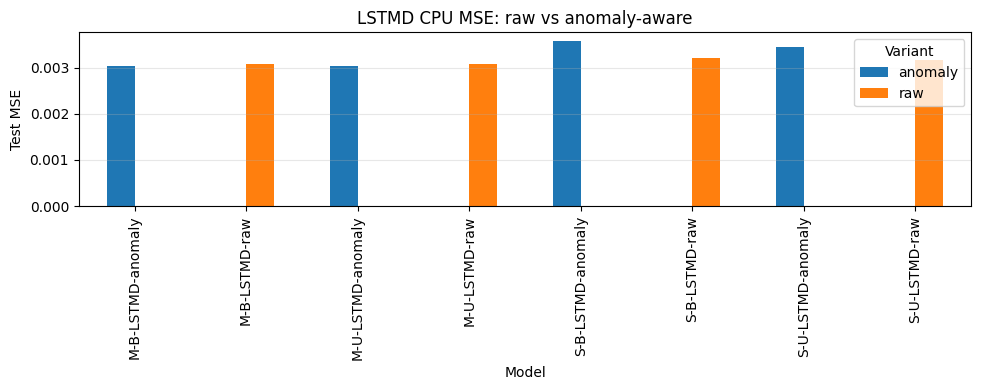


Per-fit log


,model,variant,tag,n_train,epochs_run,best_epoch,best_val_loss,train_minutes,batch_size,optimizer
0,S-U-LSTMD-raw,raw,gc11__cpu,5114,500,209,-0.369621,3.29,256,adam
1,S-U-LSTMD-raw,raw,gc11__mem,5114,500,93,-1.397383,3.91,256,adam
2,S-U-LSTMD-raw,raw,gc19_a__cpu,5114,500,139,-1.317891,4.15,256,adam
3,S-U-LSTMD-raw,raw,gc19_a__mem,5114,500,86,-1.469285,3.90,256,adam
4,S-U-LSTMD-raw,raw,gc19_b__cpu,5114,500,216,-1.306035,4.60,256,rmsprop
...,...,...,...,...,...,...,...,...,...,...
67,M-U-LSTMD-raw,raw,all__mem,63362,500,246,-1.770329,20.25,1024,rmsprop
68,M-U-LSTMD-anomaly,anomaly,all__cpu,63362,500,312,-1.645325,26.87,256,rmsprop
69,M-U-LSTMD-anomaly,anomaly,all__mem,63362,500,150,-1.760808,20.77,1024,rmsprop
70,M-B-LSTMD-raw,raw,all,63362,500,229,-3.354836,56.06,128,adam


,model,variant,resource,service_level,SR,TPR,OP,UP,spike_recall,calibration_error
0,M-B-LSTMD-anomaly,anomaly,avgcpu,0.900,88.528,109.916,10.548,0.631,3.823,-1.472
1,M-B-LSTMD-anomaly,anomaly,avgcpu,0.910,89.537,110.403,10.982,0.579,3.823,-1.463
2,M-B-LSTMD-anomaly,anomaly,avgcpu,0.920,90.601,110.931,11.459,0.528,3.823,-1.399
3,M-B-LSTMD-anomaly,anomaly,avgcpu,0.930,91.688,111.512,11.989,0.478,3.823,-1.312
4,M-B-LSTMD-anomaly,anomaly,avgcpu,0.940,92.469,112.161,12.588,0.427,3.823,-1.531
...,...,...,...,...,...,...,...,...,...,...
171,S-U-LSTMD-raw,raw,avgmem,0.960,96.145,131.974,32.254,0.280,11.150,0.145
172,S-U-LSTMD-raw,raw,avgmem,0.970,96.849,134.028,34.270,0.242,11.150,-0.151
173,S-U-LSTMD-raw,raw,avgmem,0.980,97.521,136.758,36.960,0.203,11.150,-0.479
174,S-U-LSTMD-raw,raw,avgmem,0.990,98.349,141.060,41.218,0.157,11.150,-0.651


,model,variant,resource,calibration_MAE_pp,calibration_RMSE_pp
0,M-B-LSTMD-anomaly,anomaly,avgcpu,1.383,1.393
1,M-B-LSTMD-anomaly,anomaly,avgmem,1.572,1.976
2,M-B-LSTMD-raw,raw,avgcpu,0.712,0.844
3,M-B-LSTMD-raw,raw,avgmem,0.665,0.737
4,M-U-LSTMD-anomaly,anomaly,avgcpu,1.160,1.168
5,M-U-LSTMD-anomaly,anomaly,avgmem,0.822,0.987
6,M-U-LSTMD-raw,raw,avgcpu,0.551,0.564
7,M-U-LSTMD-raw,raw,avgmem,0.665,0.754
8,S-B-LSTMD-anomaly,anomaly,avgcpu,0.439,0.508
9,S-B-LSTMD-anomaly,anomaly,avgmem,0.968,1.047


In [6]:
import matplotlib.pyplot as plt
from IPython.display import display

metrics = pd.DataFrame(state["metrics"])
agg = metrics.groupby(["variant", "model", "resource"]).agg(
    MSE=("MSE", "mean"), MAE=("MAE", "mean"), traces=("dataset", "nunique")
)
rows = []
for variant in INPUT_VARIANTS:
    for mode in ["S-U", "S-B", "M-U", "M-B"]:
        model_name = f"{mode}-{MODEL_NAME}-{variant}"
        if (variant, model_name, "avgcpu") not in agg.index or (variant, model_name, "avgmem") not in agg.index:
            continue
        c = agg.loc[(variant, model_name, "avgcpu")]
        m = agg.loc[(variant, model_name, "avgmem")]
        rows.append({"Variant": variant, "Model": model_name, "CPU_MSE": c.MSE, "CPU_MAE": c.MAE,
                     "Memory_MSE": m.MSE, "Memory_MAE": m.MAE, "traces": int(c.traces)})
comparison = pd.DataFrame(rows).round(5)
comparison.to_csv(OUT / f"{MODEL_NAME}_raw_vs_anomaly_summary.csv", index=False)
print("LSTMD comparison: original inputs vs anomaly-aware inputs")
display(comparison)

# Paired anomaly/raw ratios: below 1.0 means anomaly-aware is better.
if not metrics.empty:
    paired = metrics.pivot_table(index=["training", "dataset", "resource"], columns="variant", values=["MSE", "MAE"]).dropna()
    ratio_rows = []
    for metric in ["MSE", "MAE"]:
        ratio = paired[(metric, "anomaly")] / paired[(metric, "raw")]
        for (training, dataset, resource), value in ratio.items():
            ratio_rows.append({"metric": metric, "training": training, "dataset": dataset,
                               "resource": resource, "anomaly_over_raw": value})
    ratios = pd.DataFrame(ratio_rows)
    ratios.to_csv(OUT / f"{MODEL_NAME}_anomaly_vs_raw_ratios.csv", index=False)
    print("\nPaired ratios (below 1.0 = anomaly-aware is better):")
    display(ratios.groupby(["metric", "training", "resource"]).anomaly_over_raw.agg(["mean", "median"]).round(4))

# Paper comparison uses only the raw-input reproduction.
raw_rows = []
for mode in ["S-U", "S-B", "M-U", "M-B"]:
    model_name = f"{mode}-{MODEL_NAME}-raw"
    if ("raw", model_name, "avgcpu") not in agg.index:
        continue
    c = agg.loc[("raw", model_name, "avgcpu")]
    m = agg.loc[("raw", model_name, "avgmem")]
    pm = PAPER[f"{mode}-{MODEL_NAME}"]
    raw_rows.append({"Model": model_name, "CPU_MSE": c.MSE, "paper_CPU_MSE": pm[0],
                     "CPU_MAE": c.MAE, "paper_CPU_MAE": pm[1], "Memory_MSE": m.MSE,
                     "paper_Memory_MSE": pm[2], "Memory_MAE": m.MAE, "paper_Memory_MAE": pm[3]})
paper_cmp = pd.DataFrame(raw_rows).round(5)
paper_cmp.to_csv(OUT / f"{MODEL_NAME}_raw_vs_paper.csv", index=False)
print("\nRaw LSTMD reproduction vs paper:")
display(paper_cmp)

if not comparison.empty:
    plot_df = comparison.pivot(index="Model", columns="Variant", values="CPU_MSE")
    ax = plot_df.plot(kind="bar", figsize=(10, 4), title="LSTMD CPU MSE: raw vs anomaly-aware")
    ax.set_ylabel("Test MSE")
    ax.grid(axis="y", alpha=.3)
    plt.tight_layout()
    plt.savefig(OUT / f"{MODEL_NAME}_raw_vs_anomaly_cpu_mse.png", dpi=150)
    plt.show()

print("\nPer-fit log")
display(pd.DataFrame(state["fits"])[["model", "variant", "tag", "n_train", "epochs_run", "best_epoch",
                                     "best_val_loss", "train_minutes", "batch_size", "optimizer"]])


# Paper-aligned service-level summary: SR, TPR, OP and UP.
service_df = pd.DataFrame(state["service"])
if not service_df.empty:
    service_summary = service_df.groupby(["model", "variant", "resource", "service_level"]).agg(
        SR=("SR", "mean"), TPR=("TPR", "mean"), OP=("OP", "mean"), UP=("UP", "mean"),
        spike_recall=("spike_recall", "mean"), calibration_error=("calibration_error", "mean")
    ).reset_index()
    service_summary.to_csv(OUT / f"{MODEL_NAME}_service_summary.csv", index=False)
    display(service_summary.round(3))

    calibration = service_summary.groupby(["model", "variant", "resource"]).apply(
        lambda g: pd.Series({
            "calibration_MAE_pp": np.mean(np.abs(g["SR"].to_numpy() - g["service_level"].to_numpy()*100)),
            "calibration_RMSE_pp": np.sqrt(np.mean((g["SR"].to_numpy() - g["service_level"].to_numpy()*100)**2))
        }), include_groups=False
    ).reset_index()
    calibration.to_csv(OUT / f"{MODEL_NAME}_calibration_summary.csv", index=False)
    display(calibration.round(3))


## 6. Verify saved models and zip everything

Models are saved as `.keras` and their output is `[mean | raw_scale]`. To reuse one elsewhere:

```python
m = keras.models.load_model(path, compile=False)
raw = m.predict(X)                      # X: (N, 288, channels)
d = raw.shape[-1] // 2
mean, std = raw[:, :d], np.logaddexp(0, raw[:, d:])
```

In [7]:
# Sanity check: reload one saved model and compare with the stored predictions
fit = state["fits"][-1]
reloaded = keras.models.load_model(OUT / "models" / fit["model_file"], compile=False)
mode = fit["model"].split("-LSTMD")[0]
variant = fit.get("variant", "raw")
job = next(j for j in jobs_for(mode, variant) if j["tag"] == fit["tag"])
t0 = job["eval"][0]
in_cols = input_columns(job["cols"], variant)
Xte = WINDOWS[t0][4][:, :, in_cols][:256]
mean, _ = mean_std(reloaded.predict(Xte, verbose=0))
stored = state["preds"][mode + "__" + variant]
stored = stored[(stored.dataset == t0) & (stored.resource == RESOURCES[job["cols"][0]])].sort_values("step")["pred"].to_numpy()[:len(mean)]
print(f"Reloaded {fit['model_file']}: max |reloaded - stored prediction| = {np.abs(mean[:, 0] - stored).max():.2e}")

zip_path = OUT.parent / f"{MODEL_NAME}_anomaly_results.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for f in sorted(OUT.rglob("*")):
        if f.is_file() and f.parent.name != "ckpt":
            z.write(f, f.relative_to(OUT.parent))
print("\nFiles in", OUT)
for f in sorted(OUT.glob("*.csv")) + sorted(OUT.glob("*.png")):
    print(f"  {f.name:42s} {f.stat().st_size/1e3:9.1f} KB")
print(f"  models/: {len(list((OUT/'models').glob('*.keras')))} .keras files | history/: {len(list((OUT/'history').glob('*.csv')))} | predictions/: {len(list((OUT/'predictions').glob('*.csv')))}")
print("ZIP:", zip_path, f"({zip_path.stat().st_size/1e6:.1f} MB)")


Reloaded M-B-LSTMD-anomaly__all.keras: max |reloaded - stored prediction| = 2.38e-07

Files in /kaggle/working/lstmd_11trace_anomaly_output_v2
  LSTMD_anomaly_vs_raw_ratios.csv                  7.9 KB
  LSTMD_calibration_summary.csv                    1.1 KB
  LSTMD_fit_log.csv                               10.2 KB
  LSTMD_model_metrics.csv                         16.0 KB
  LSTMD_raw_vs_anomaly_summary.csv                 0.5 KB
  LSTMD_raw_vs_paper.csv                           0.4 KB
  LSTMD_service_level_metrics.csv                458.5 KB
  LSTMD_service_summary.csv                       25.9 KB
  LSTMD_raw_vs_anomaly_cpu_mse.png                56.8 KB
  models/: 72 .keras files | history/: 72 | predictions/: 8
ZIP: /kaggle/working/LSTMD_anomaly_results.zip (31.1 MB)


In [8]:
# Recompute paper-aligned service metrics from saved predictions.
# This also corrects older resumed runs without retraining the models.
service_rows = []
for key, pdf in state["preds"].items():
    if pdf.empty:
        continue
    for (model, variant, trace, resource), g in pdf.groupby(["model", "variant", "dataset", "resource"]):
        g = g.sort_values("step")
        actual = g["label"].to_numpy(dtype=float)
        mean = g["pred"].to_numpy(dtype=float)
        std = g["std"].to_numpy(dtype=float)
        demand_total = float(np.sum(actual))
        for q in SERVICE_LEVELS:
            upper = np.maximum(mean + NormalDist().inv_cdf(q) * std, 0.0)
            covered = actual <= upper
            sr = 100.0 * np.mean(covered)
            tpr_resources = 100.0 * np.sum(upper) / demand_total if demand_total > 0 else np.nan
            op = 100.0 * np.sum(np.maximum(upper[covered] - actual[covered], 0.0)) / demand_total if demand_total > 0 else np.nan
            up = 100.0 * np.sum(np.maximum(actual[~covered] - upper[~covered], 0.0)) / demand_total if demand_total > 0 else np.nan
            spike_actual = g["spike_actual"].to_numpy(dtype=bool)
            spike_pred = g["spike_pred"].to_numpy(dtype=bool)
            tp = int(np.sum(spike_actual & spike_pred)); fn = int(np.sum(spike_actual & ~spike_pred))
            spike_recall = 100.0 * tp / (tp + fn) if tp + fn else np.nan
            service_rows.append(dict(model=model, variant=variant, dataset=trace, resource=resource,
                service_level=q, SR=sr, TPR=tpr_resources, OP=op, UP=up,
                spike_recall=spike_recall, calibration_error=sr-q*100.0))
service_df = pd.DataFrame(service_rows)
if not service_df.empty:
    service_df.to_csv(OUT / f"{MODEL_NAME}_service_level_metrics.csv", index=False)
    service_summary = service_df.groupby(["model", "variant", "resource", "service_level"]).agg(
        SR=("SR", "mean"), TPR=("TPR", "mean"), OP=("OP", "mean"), UP=("UP", "mean"),
        spike_recall=("spike_recall", "mean"), calibration_error=("calibration_error", "mean")
    ).reset_index()
    service_summary.to_csv(OUT / f"{MODEL_NAME}_service_summary.csv", index=False)
    display(service_summary.round(3))
    calibration = service_summary.groupby(["model", "variant", "resource"]).apply(
        lambda g: pd.Series({
            "calibration_MAE_pp": np.mean(np.abs(g["SR"].to_numpy()-g["service_level"].to_numpy()*100)),
            "calibration_RMSE_pp": np.sqrt(np.mean((g["SR"].to_numpy()-g["service_level"].to_numpy()*100)**2))
        }), include_groups=False
    ).reset_index()
    calibration.to_csv(OUT / f"{MODEL_NAME}_calibration_summary.csv", index=False)
    display(calibration.round(3))


KeyError: 'label'